In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../backend")
from nlp_utils import clean_text

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_excel("../data/dataset_chatbot_kesehatan.xlsx", sheet_name="Dataset")
df["pertanyaan"] = df["pertanyaan"].astype(str).str.strip()
df["clean"] = df["pertanyaan"].apply(clean_text)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"],
    test_size=0.2, stratify=df["intent"], random_state=42)
print(len(X_train), "data latih |", len(X_test), "data uji")

384 data latih | 96 data uji


In [2]:
tfidf_a = TfidfVectorizer(ngram_range=(1, 2))
Xtr_a = tfidf_a.fit_transform(X_train)

def predict_retrieval(texts):
    sims = cosine_similarity(tfidf_a.transform(texts), Xtr_a)  # kemiripan ke semua pertanyaan latih
    best = sims.argmax(axis=1)                                 # indeks pertanyaan paling mirip
    return y_train.iloc[best].values, sims.max(axis=1)

pred_a, score_a = predict_retrieval(X_test)
print("Akurasi A:", accuracy_score(y_test, pred_a))
print(classification_report(y_test, pred_a, zero_division=0))

Akurasi A: 0.4583333333333333
                       precision    recall  f1-score   support

      aktivitas_fisik       0.60      0.75      0.67         4
         definisi_gdm       0.20      0.25      0.22         4
        di_luar_topik       1.00      0.75      0.86         4
        diagnosis_gdm       0.12      0.25      0.17         4
    faktor_risiko_gdm       0.00      0.00      0.00         4
    hipoglikemia_bayi       0.40      0.50      0.44         4
 kenaikan_berat_badan       1.00      0.75      0.86         4
         ketoasidosis       0.50      0.75      0.60         4
      komplikasi_bayi       0.25      0.25      0.25         4
       komplikasi_ibu       0.00      0.00      0.00         4
             menyusui       0.40      0.50      0.44         4
            obat_oral       1.00      0.50      0.67         4
      pascapersalinan       0.20      0.25      0.22         4
   pemantauan_glukosa       0.00      0.00      0.00         4
       pencegahan_gdm   

Akurasi B: 0.65625
                       precision    recall  f1-score   support

      aktivitas_fisik       0.75      0.75      0.75         4
         definisi_gdm       1.00      0.25      0.40         4
        di_luar_topik       0.80      1.00      0.89         4
        diagnosis_gdm       0.50      0.50      0.50         4
    faktor_risiko_gdm       0.40      0.50      0.44         4
    hipoglikemia_bayi       0.60      0.75      0.67         4
 kenaikan_berat_badan       1.00      1.00      1.00         4
         ketoasidosis       1.00      1.00      1.00         4
      komplikasi_bayi       0.60      0.75      0.67         4
       komplikasi_ibu       0.00      0.00      0.00         4
             menyusui       1.00      0.50      0.67         4
            obat_oral       1.00      0.75      0.86         4
      pascapersalinan       1.00      0.50      0.67         4
   pemantauan_glukosa       0.00      0.00      0.00         4
       pencegahan_gdm       0.75   

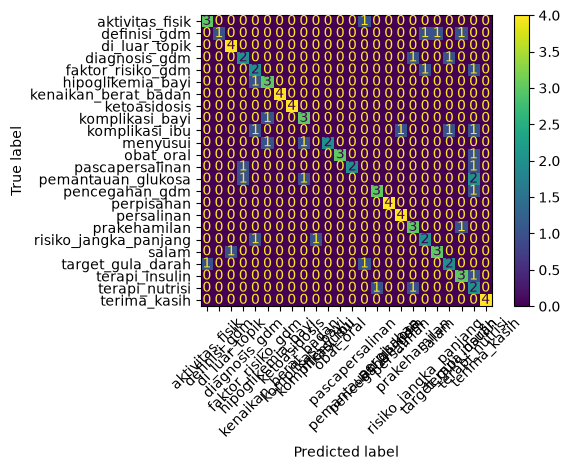

In [3]:
def make_pipe():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("lr", LogisticRegression(max_iter=2000, C=10)),
    ])

model_b = make_pipe()
t0 = time.time()
model_b.fit(X_train, y_train)
time_b = time.time() - t0

pred_b = model_b.predict(X_test)
print("Akurasi B:", accuracy_score(y_test, pred_b))
print(classification_report(y_test, pred_b, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred_b, xticks_rotation=45)
plt.tight_layout(); plt.show()

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(make_pipe(), df["clean"], df["intent"], cv=cv, scoring="f1_macro")
print("F1-macro per fold:", scores.round(3), "| rata-rata:", scores.mean().round(3))

F1-macro per fold: [0.727 0.651 0.697 0.605 0.632] | rata-rata: 0.662


In [5]:
for use_stem in [False, True]:
    texts = df["pertanyaan"].apply(lambda t: clean_text(t, use_stemming=use_stem))
    s = cross_val_score(make_pipe(), texts, df["intent"], cv=cv, scoring="f1_macro").mean()
    print(f"stemming={use_stem}: F1-macro = {s:.3f}")

stemming=False: F1-macro = 0.662
stemming=True: F1-macro = 0.699


In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import LabelEncoder

tf.keras.utils.set_random_seed(42)

le = LabelEncoder()
y_tr = le.fit_transform(y_train)
y_te = le.transform(y_test)

tok = Tokenizer(oov_token="<OOV>")
tok.fit_on_texts(X_train)
MAXLEN = 15          # sesuaikan dengan panjang maksimum dari notebook 01
VOCAB = len(tok.word_index) + 1

def to_seq(texts):
    return pad_sequences(tok.texts_to_sequences(texts), maxlen=MAXLEN, padding="post")

Xtr_seq, Xte_seq = to_seq(X_train), to_seq(X_test)

def build_model(kind="bilstm", units=32, dropout=0.3):
    rnn = layers.GRU(units) if kind == "gru" else layers.Bidirectional(layers.LSTM(units))
    m = models.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(VOCAB, 64, mask_zero=True),
        rnn,
        layers.Dropout(dropout),
        layers.Dense(len(le.classes_), activation="softmax"),
    ])
    m.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return m

def train_eval(kind, units, dropout):
    m = build_model(kind, units, dropout)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    m.fit(Xtr_seq, y_tr, validation_split=0.2, epochs=150,
          batch_size=8, callbacks=[es], verbose=0)
    dur = time.time() - t0
    pred = m.predict(Xte_seq, verbose=0).argmax(axis=1)
    return accuracy_score(y_te, pred), f1_score(y_te, pred, average="macro"), dur

rows = []
for kind in ["bilstm", "gru"]:
    for units in [32, 64]:
        for dropout in [0.3, 0.5]:
            acc, f1, dur = train_eval(kind, units, dropout)
            rows.append({"model": kind, "units": units, "dropout": dropout,
                         "akurasi": round(acc, 3), "f1_macro": round(f1, 3),
                         "waktu_train_s": round(dur, 1)})
            print(rows[-1])
df_neural = pd.DataFrame(rows)
df_neural

{'model': 'bilstm', 'units': 32, 'dropout': 0.3, 'akurasi': 0.531, 'f1_macro': 0.538, 'waktu_train_s': 17.3}
{'model': 'bilstm', 'units': 32, 'dropout': 0.5, 'akurasi': 0.604, 'f1_macro': 0.607, 'waktu_train_s': 16.5}
{'model': 'bilstm', 'units': 64, 'dropout': 0.3, 'akurasi': 0.604, 'f1_macro': 0.606, 'waktu_train_s': 16.7}
{'model': 'bilstm', 'units': 64, 'dropout': 0.5, 'akurasi': 0.562, 'f1_macro': 0.543, 'waktu_train_s': 19.1}
{'model': 'gru', 'units': 32, 'dropout': 0.3, 'akurasi': 0.51, 'f1_macro': 0.497, 'waktu_train_s': 12.4}
{'model': 'gru', 'units': 32, 'dropout': 0.5, 'akurasi': 0.531, 'f1_macro': 0.525, 'waktu_train_s': 14.1}
{'model': 'gru', 'units': 64, 'dropout': 0.3, 'akurasi': 0.51, 'f1_macro': 0.497, 'waktu_train_s': 11.6}
{'model': 'gru', 'units': 64, 'dropout': 0.5, 'akurasi': 0.562, 'f1_macro': 0.556, 'waktu_train_s': 12.2}


,model,units,dropout,akurasi,f1_macro,waktu_train_s
0,bilstm,32,0.3,0.531,0.538,17.3
1,bilstm,32,0.5,0.604,0.607,16.5
2,bilstm,64,0.3,0.604,0.606,16.7
3,bilstm,64,0.5,0.562,0.543,19.1
4,gru,32,0.3,0.510,0.497,12.4
5,gru,32,0.5,0.531,0.525,14.1
6,gru,64,0.3,0.510,0.497,11.6
7,gru,64,0.5,0.562,0.556,12.2


In [7]:
hasil = pd.DataFrame([
    {"model": "A. Retrieval TF-IDF+Cosine", "akurasi": accuracy_score(y_test, pred_a),
     "f1_macro": f1_score(y_test, pred_a, average="macro")},
    {"model": "B. TF-IDF+LogReg", "akurasi": accuracy_score(y_test, pred_b),
     "f1_macro": f1_score(y_test, pred_b, average="macro")},
]).round(3)
print(hasil)
print(df_neural.sort_values("f1_macro", ascending=False).head(3))

                        model  akurasi  f1_macro
0  A. Retrieval TF-IDF+Cosine    0.458     0.450
1            B. TF-IDF+LogReg    0.656     0.646
    model  units  dropout  akurasi  f1_macro  waktu_train_s
1  bilstm     32      0.5    0.604     0.607           16.5
2  bilstm     64      0.3    0.604     0.606           16.7
7     gru     64      0.5    0.562     0.556           12.2


In [9]:
# --- Latih ulang pada SEMUA data lalu simpan ---
import os, json, joblib

final_model = make_pipe()
final_model.fit(df["clean"], df["intent"])

os.makedirs("../backend/model", exist_ok=True)
joblib.dump(final_model, "../backend/model/intent_model.joblib")

answers = df.groupby("intent")["jawaban"].first().to_dict()
with open("../backend/model/answers.json", "w", encoding="utf-8") as f:
    json.dump(answers, f, ensure_ascii=False, indent=2)
print("Tersimpan:", list(answers.keys()))

Tersimpan: ['aktivitas_fisik', 'definisi_gdm', 'di_luar_topik', 'diagnosis_gdm', 'faktor_risiko_gdm', 'hipoglikemia_bayi', 'kenaikan_berat_badan', 'ketoasidosis', 'komplikasi_bayi', 'komplikasi_ibu', 'menyusui', 'obat_oral', 'pascapersalinan', 'pemantauan_glukosa', 'pencegahan_gdm', 'perpisahan', 'persalinan', 'prakehamilan', 'risiko_jangka_panjang', 'salam', 'target_gula_darah', 'terapi_insulin', 'terapi_nutrisi', 'terima_kasih']


In [10]:
# --- Tentukan threshold dengan membandingkan pertanyaan relevan vs di luar topik ---
proba_in = model_b.predict_proba(X_test).max(axis=1)
oos = ["cara membuat nasi goreng", "siapa presiden indonesia",
       "apa itu flu", "harga laptop murah", "rekomendasi film bagus"]
proba_out = model_b.predict_proba([clean_text(t) for t in oos]).max(axis=1)
print("Confidence pertanyaan relevan (min/rata-rata):", proba_in.min().round(2), proba_in.mean().round(2))
print("Confidence pertanyaan di luar topik:", proba_out.round(2))

Confidence pertanyaan relevan (min/rata-rata): 0.09 0.44
Confidence pertanyaan di luar topik: [0.72 0.71 0.11 0.22 0.47]
